Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE", as well as your name and collaborators below:

In [1]:
NAME = "Shehab Ibrahim"
COLLABORATORS = ""

---

# Computational Complexity

One of the differentiating characteristics of Big Data as compared to more traditional data is the much larger amount of resources typically required to process it. One therefore has to estimate the required amount of resources to process the input data before starting to process it lest risk the possibility of wasting time and resources on something that is ultimately futile.

The amount of resources required to run an algorithm is known as its _computational complexity_ or simply, _complexity_. It is usually expressed as a function of the size of the input data $n$, and may refer to the _worst-case complexity_ (maximum amount of resources needed among all possible inputs of size $n$) or _average-case complexity_ (expected amount of resources among all possible inputs of size $n$). 

The resources most commonly considered is time (_time complexity_) and, much less commonly, space (_space complexity_). The time complexity is usually measured in terms of the number of _steps_ to perform the algorithm with the assumption that each step takes a constant amount of time. To convert the time complexity into an estimate of the execution time, we multiply the number of estimates with the execution time of each step. Space complexity refers to the amount of random access memory (RAM) needed to perform the algorithm--data must first be loaded into memory (RAM) before it can be processed. Though not as popular, other resources may also be considered as well such as the amount of persistent storage (hard drive or SSD) required and network bandwidth.

The fields of _Analysis of Algorithms_ and _Computational Complexity Theory_ deal with the estimation of the computational complexity of algorithms and problems, respectively. We won't go into that level of detail and we will proceed in a nonrigorous manner. The purpose of this notebook is to familiarize you with the terms and theoretical concepts so that you won't be surprised when you encounter these terms and concepts in the future. You will learn empirical approaches to estimating the computational complexity and profiling code later in this notebook.

# Estimating time and space complexity

The simplest way of estimating computational complexity is to count the number of times the input is read or goes through a loop. For example, consider the function `list_max` which returns the maximum value in list `a`, which is of length $n$.

    def list_max(a):
        """Compute the maximum element in the array a"""
        max_val = a[0]
        for i in a[1:]:
            if i > max
                max_val = i
        return max_val

To estimate the time complexity of `list_max`, we count the number of times (steps) an elementary operation is performed by the algorithm. We choose the elementary operation as the operation that is performed frequently by the algorithm and has the following properties:

* There can't be any other operations that are performed more frequently as the size of the input grows.
* The time to execute an elementary operation must be constant: it mustn't increase as the size of the input grows.

For this example, we choose the comparison `i > max` as the elementary operation. For $n > 0$, $n - 1$ comparisons are performed so we write it down as $T(n) = n - 1$. 

The function only needs to allocate memory for the variable `max_val` to run the algorithm, so the space complexity $S(n) = 1$ where 1 actually corresponds to the size of an element in `a`.

Let us look at another example:

    def contains(a, x):
        """Tell whether the array a contains x"""
        for i in a:
            if x == i:
                return True
        return False

The elementary operation is the comparison `if x == i`. Now depending on whether `x` is in `a` and on where in `a` `x` is, the running time of `contains` would range from 1 to `n` (where `n` is the length of `a`). The usual approach is to consider the _worst-case_ time complexity: in this case, it's `n`. The other approach is to consider the _average-case_ time complexity, which is the sum of the time complexities for each possible value of `n` weighted by the probability of `n` i.e., the expected time complexity. The average-case complexity is more difficult to compute since you need the distribution of inputs of size `n` but it makes more sense if the worst-case is an outlier or a rare case. 

The function did not allocate any space for a variable so its space complexity is zero.

## Asymptotic complexity and the Big-O notation

Consider the function below:

    def reverse(a):
        """Reverse the order of the elements in the array a"""
        for i in range(1, len(a)):
            x = a[i]
            for j in range(i, 0, -1):
                a[j] = a[j-1]
            a[0] = x
            
The elementary operation is the assignment `a[j] = a[j-1]`. For every `i`, `i-1` assignments must be performed. Thus for an array size $n>0$, the number of steps (assignments) that will be performed are $0 + 1 + 2 + 3 + ... + (n - 1) = n(n-1)/2 = n^2 - n/2$. For large input data i.e., $n \rightarrow \infty$, the $n^2$ term dominates and so we write the asymptotic (time) complexity as $T(n) \in O(n^2)$. The only memory space that we need to allocate is the one for `x` and that is constant so, the space complexity and asymptotic space complexity are both $O(1)$.

Let us consider another implementation of the reverse function:

    def reverse2(a):
        """Reverse the order of the elements in the array a"""
        for i in range(0, len(a)//2):
            a[-i], a[i] = a[i], a[-i] # swap
            
The swap operation is the elementary operation for `reverse2`. For an array size $n>0$, `n/2` swaps need to be performed and so the asymptotic time complexity is $O(n)$. The swap operation internally creates an intermediate variable but, nevertheless, the asymptotic space complexity is still constant: $O(1)$.

The asymptotic complexity is particularly important for big data analytics because of the size of input data we usually work on. In the examples above, we say that `reverse2` scales better than `reverse` because $O(n)$ grows slower than $O(n^2)$. So what does this mean in practical terms? Let's say that it takes you 1 ms to process a single tweet. If you have 1M tweets to process then a quadratic time complexity algorithm ($O(n^2)$) would take $(10^6)^2 \times 10^{-3}\text{ s} = 10^9 \text{ s} \approx 10,000 \text{ years}$ compared to a linear time complexity algorithm ($O(n)$) that would only take $(10^6)(10^{-3}\text{ s})=10^3 \text{ s} \approx 17\text{ minutes}$.

Examples of families of computational complexity include linear ($O(n)$), quadratic ($O(n^2)$), cubic ($O(n^3)$), logarithmic ($O(\log n)$) and exponential ($O(exp(n))$). We usually want the computational complexity to be small. In the given examples of families, $O(\log n) < O(n) < O(n^2) < O(n^3) < O(\exp(n)$.

Remember that asymptotic complexity is for the $n \rightarrow \infty$ case. In many instances, an algorithm designed for smaller data can easily beat an algorithm with better asymptotic complexity with smaller input data due to the usually bigger overhead of algorithms designed for larger data.

## Measuring execution time

While the computational complexity of the examples above are not difficult to estimate, the computational complexity of many real-world algorithms is not as easy to compute just by looking at the source code. In practice, many seasoned programmers have a general idea of the complexity of the new algorithm that they're writing but only to the level of whether it's polynomial, sublinear, exponential and so on. For many classic algorithms e.g., those used in sorting and search, they're computational complexities are already well known and can be easily looked up. However, for new algorithms and code that we write, is there a way to more conveniently estimate their computational complexity and execution time? Fortunately, there is and it's as simple as measuring the execution time of the code as we vary the size of the input.

So how do we measure the execution time of a Python code?

The simplest approach is to assign the start time of the code you want to measure then subtract the start time from the time the code finished:

In [4]:
import numpy as np
a = np.arange(10000)

%timeit a**2
%timeit [i**2 for i in a]

9.94 µs ± 129 ns per loop (mean ± std. dev. of 7 runs, 100000 loops each)
2.46 ms ± 50 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [2]:
import time

def reverse(a):
    """Reverse the order of the elements in the array a"""
    time_start = time.time()
    for i in range(1, len(a)):
        x = a[i]
        for j in range(i, 0, -1):
            a[j] = a[j-1]
        a[0] = x
    print('Execution time in seconds:', time.time() - time_start)

In [3]:
reverse(list(range(100)))

Execution time in seconds: 0.0010001659393310547


In [4]:
reverse(list(range(1000)))

Execution time in seconds: 0.058141231536865234


In [5]:
reverse(list(range(10000)))

Execution time in seconds: 5.968031167984009


For small code snippets, you may use the [`timeit`](https://docs.python.org/3/library/timeit.html) module. It runs the code being measured in its own environment so it avoids many of the pitfalls of measuring execution times on Python.

In [6]:
import timeit

timeit.timeit('list(reversed(range(100)))')

2.1668102806794423

Since it runs the code in its own environment, you need to specify `import` statements and other setup code.

In [7]:
timeit.timeit('np.arange(100)[::-1]', setup='import numpy as np')

1.0124811346061886

When timing code that runs quickly (less than 0.2 s), the overhead for setting up and calling the code is no longer negligible compared to the execution time of the code you are timing. Thus, the default is to run the code snippet 1M times. You may reduce it for longer running code.

In [8]:
timeit.timeit('list(reversed(range(100)))', number=100000)

0.23296307821362916

If the code snippet uses variables and functions in the current namespace, then you need to pass the output of `globals()` to the `globals` parameter.

In [11]:
def reverse2(a):
    """Reverse the order of the elements in the array a"""
    for i in range(0, len(a)//2):
        a[-i], a[i] = a[i], a[-i] # swap

# we time `reverse2` instead of `reverse` to avoid the flood of `print` 
# statements
timeit.timeit('reverse2(list(range(100)))', number=100000, globals=globals())

1.0186710657494586

IPython (Jupyter) also has the `%timeit` magic that allows calling `timeit` in the cell. It has the advantage of automatically selecting the number of iterations as well as a more convenient output of execution time statistics.

In [10]:
%timeit reverse2(list(range(100)))

10.4 µs ± 206 ns per loop (mean ± std. dev. of 7 runs, 100000 loops each)


For longer running code, you may want to know how long it takes to run without manually adding code for measuring the elapsed time. The `%time` magic allows you to conveniently do this.

In [11]:
%time reverse2(list(range(100)))

Wall time: 0 ns


The Wall time is the time it took to run the code considering all overheads and delays. This is the time elapsed when you use a (wall) clock to time the execution.

The problem with using `%time` is that you have to put it in before running the cell. What if you run a cell then you realize that it takes longer than expected? You want to know how long it runs so that you would know how long it would take if you run it again as well as for estimating the computational complexity. A better approach is to time the execution of all cells and a convenient way of doing that is by using the [`ExecuteTime`](https://jupyter-contrib-nbextensions.readthedocs.io/en/latest/nbextensions/execute_time/readme.html) Jupyter notebook extension, which I hope you have already enabled.

After measuring the execution times for different values of input size, you can then plot the execution time vs the input size and fit a curve. The curve would be the code's asymptotic time complexity. The same fit would also allow you to extrapolate the actual execution time of the code for a certain input size, and not just its computational complexity.

In [12]:
import numpy as np
input_sizes = np.logspace(0, 5, num=10)
repetitions = 1000
exec_times = [timeit.timeit('reverse2(list(range(%d)))' % input_size, 
                            number=repetitions, 
                            globals=globals()) / repetitions 
              for input_size in input_sizes]

linear (R^2): 0.9990656394240113
quadratic (R^2): 0.9488502048596813


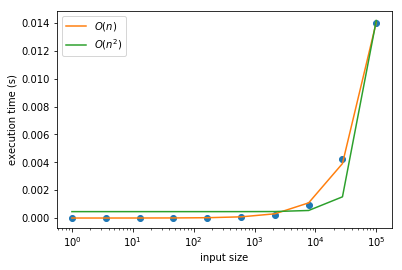

In [13]:
import matplotlib.pyplot as plt
from scipy.stats import linregress, pearsonr
from scipy.optimize import curve_fit
%matplotlib inline

slope, intercept, rvalues, _, _ = linregress(input_sizes, exec_times)
y_lin = slope * input_sizes + intercept

def quad(x, a, y0):
    return a*x**2 + y0
popt, _ = curve_fit(quad, input_sizes, exec_times)
y_quad = quad(input_sizes, *popt)

plt.semilogx(input_sizes, exec_times, 'o')
plt.semilogx(input_sizes, y_lin, label='$O(n)$')
plt.semilogx(input_sizes, y_quad, label='$O(n^2)$')
plt.xlabel('input size')
plt.ylabel('execution time (s)')
plt.legend()

print('linear (R^2):', rvalues**2)
print('quadratic (R^2):', pearsonr(exec_times, y_quad)[0]**2)

**Exercise:** Fit a curve that corresponds to $O(\log n)$ on the execution times above.

linear (R^2): 0.9999455586670796
quadratic (R^2): 0.9618684590523773
logarithmic (R^2): 0.43819212140778


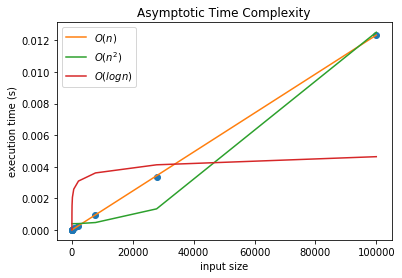

In [16]:
import matplotlib.pyplot as plt
from scipy.stats import linregress, pearsonr
#from scipy.stats import l
from scipy.optimize import curve_fit
%matplotlib inline

slope, intercept, rvalues, _, _ = linregress(input_sizes, exec_times)
y_lin = slope * input_sizes + intercept

def quad(x, a, y0):
    return a*x**2 + y0
popt, _ = curve_fit(quad, input_sizes, exec_times)
y_quad = quad(input_sizes, *popt)


def log(x, a):
    return a*(np.log(x))
popt, _ = curve_fit(log, input_sizes, exec_times)
y_log = log(input_sizes, *popt)


# plt.semilogx(input_sizes, exec_times, 'o')
# plt.semilogx(input_sizes, y_lin, label='$O(n)$')
# plt.semilogx(input_sizes, y_quad, label='$O(n^2)$')
# plt.semilogx(input_sizes, y_log, label='$O(logn)$')

plt.plot(input_sizes, exec_times, 'o')
plt.plot(input_sizes, y_lin, label='$O(n)$')
plt.plot(input_sizes, y_quad, label='$O(n^2)$')
plt.plot(input_sizes, y_log, label='$O(logn)$')


plt.xlabel('input size')
plt.ylabel('execution time (s)')
plt.title("Asymptotic Time Complexity")
plt.legend()

print('linear (R^2):', rvalues**2)
print('quadratic (R^2):', pearsonr(exec_times, y_quad)[0]**2)
print('logarithmic (R^2):', pearsonr(exec_times, y_log)[0]**2)

**Exercise:** Which among $O(\log n)$, $O(n)$ and $O(n^2)$, is the best estimate of the code's aymptotic time complexity? Explain your answer.

Clearly shown at the plot above, the  $O(n)$ has the best estimate of the reverse2 function code's asymptotic time complexity. This concurs on how the code inside the function reverse2 is organized: 
<br> &nbsp;&nbsp;    for i in range(0, len(a)//2):
<br> &nbsp; &nbsp;&nbsp;        $ a[-i], a[i] = a[i], a[-i]$
<br> It evidently shows that it is linear thus producing an asymptotic time complexity of $O(n)$ .

**Exercise:** Estimate the execution time for an input size of 1M.

The execution time for an input size of 1M is : 0.13177767208291596


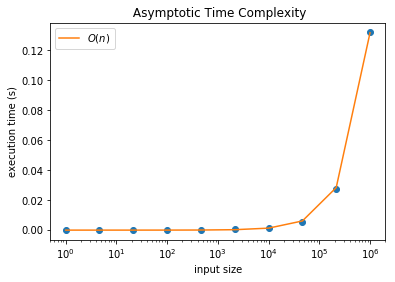

In [18]:
input_sizes = np.logspace(0, 6, num=10)
repetitions = 1000
exec_times = [timeit.timeit('reverse2(list(range(%d)))' % input_size, 
                            number=repetitions, 
                            globals=globals()) / repetitions 
              for input_size in input_sizes]


slope, intercept, rvalues, _, _ = linregress(input_sizes, exec_times)
y_lin = slope * input_sizes + intercept



plt.semilogx(input_sizes, exec_times, 'o')
plt.semilogx(input_sizes, y_lin, label='$O(n)$')

plt.xlabel('input size')
plt.ylabel('execution time (s)')
plt.title(' Asymptotic Time Complexity')
plt.legend()

exec_time_1M  = slope * 1000000 + intercept
print("The execution time for an input size of 1M is :" , exec_time_1M)


Unfortunately, if you're using `%timeit`, `%time` and `ExecuteTime`, you have to manually change the input size and write down the execution time.

# Code profiling

In many instances, the code you are interested in calls other functions as well. This creates a web of function calls which makes it more difficult to pinpoint which part of the code is the bottleneck. When optimizing code, one targets the bottlenecks.

A tool that times parts of a code including function calls is known as a code profiler. Python has two built-in code profilers: `cProfile` and `profile`. We will only work with `cProfile` because the latter is only used if we want to extend the code profiler.

In [3]:
import cProfile
import numpy as np
def all_max(a):
    """Return the largest value in a nested list of numbers"""
    return max([list_max(row) for row in a])

def list_max(a):
    """Return largest value in list a"""
    return max(a)

When you call `cProfile.run`, you will get a table of results.

In [4]:
a = np.random.randint(0, 100, (10000, 10000))
cProfile.run('all_max(a)')

         20006 function calls in 8.002 seconds

   Ordered by: standard name

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    8.002    8.002 <ipython-input-3-959018c6d371>:3(all_max)
        1    0.010    0.010    8.001    8.001 <ipython-input-3-959018c6d371>:5(<listcomp>)
    10000    0.005    0.000    7.991    0.001 <ipython-input-3-959018c6d371>:7(list_max)
        1    0.000    0.000    8.002    8.002 <string>:1(<module>)
        1    0.000    0.000    8.002    8.002 {built-in method builtins.exec}
    10001    7.986    0.001    7.986    0.001 {built-in method builtins.max}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}




The following are the meaning of each column:

* `ncalls` for the number of calls.
* `tottime` for the total time spent in the given function (and excluding time made in calls to sub-functions)
* `percall` is the quotient of tottime divided by ncalls
* `cumtime` is the cumulative time spent in this and all subfunctions (from invocation till exit). This figure is accurate even for recursive functions.
* `percall` is the quotient of cumtime divided by primitive calls
* `filename:lineno(function)` provides the respective data of each function

Functions or methods that have high `ncalls` are good to target because a slight improvement on it may lead to a huge improvement in runtime especially if it also has a large `tottime` or `cumtime`. A higher `percall tottime` than `percall cumtime` may mean most of the runtime is spent on the actual code itself and not on function calls--thus the optimization effort may focus on improving the code in the function. If it's the other way around, one may look at the performance of the functions the code is calling or perhaps, make the called function inline.

One may also save the output of `cProfile.run` to a file. This would allow better manipulation and printing of the table.

In [7]:
cProfile.run('all_max(a)', 'allmaxstats')

In [8]:
import pstats
p = pstats.Stats('allmaxstats')
p.strip_dirs().sort_stats('cumulative').print_stats()

Fri Sep 21 11:24:05 2018    allmaxstats

         20006 function calls in 7.632 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    7.632    7.632 {built-in method builtins.exec}
        1    0.000    0.000    7.632    7.632 <string>:1(<module>)
        1    0.000    0.000    7.632    7.632 <ipython-input-3-959018c6d371>:3(all_max)
        1    0.009    0.009    7.632    7.632 <ipython-input-3-959018c6d371>:5(<listcomp>)
    10000    0.006    0.000    7.623    0.001 <ipython-input-3-959018c6d371>:7(list_max)
    10001    7.617    0.001    7.617    0.001 {built-in method builtins.max}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}




You may also invoke the `%prun` magic to profile code.

In [10]:
%prun all_max(a)

Note that the code to be profiled need not be a function. It can be any code snippet.

In [21]:
import re
%prun re.compile("foo|bar")

## Measuring memory usage

The module [`memory_profiler`](https://pypi.org/project/memory_profiler/) can return the line-by-line memory consumption of a function. It is not a built-in module and has to be installed using `conda` or `pip`.

To profile a function, decorate it with `memory_profiler.profile`, save it to a python file then call `python -m memory_profiler` with the filename as the argument. However, we prefer doing everything in the notebook so we instead use the `%memit` magic.

We first load it on the kernel.

In [11]:
%load_ext memory_profiler

Then we simply call the code that we want to profile with the `%memit` magic.

In [12]:
def all_square(a):
    """Return the square of all numbers in a nested list"""
    squared = []
    for row in a:
        squared.append(list_square(row))
    return squared

def list_square(a):
    """Return the square of each element in a"""
    return [elem**2 for elem in a]

In [14]:
%memit all_square(a)

peak memory: 3543.50 MiB, increment: 3481.51 MiB


A disadvantage of using `memory_profiler` and `%memit` is that you have to call them beforehand. For currently running code, one may prefer to look at the memory usage of the currently running Python process. To do so, on Linux, open a terminal (or create a new terminal on Jupyterhub) and run `top`. Press `c` to show the arguments of each command. You need this to distinguish the many `python` processes that usually run on a machine.

Other `top` hotkeys that you may find useful are:
* `e`: Change the tasks memory scale (bytes, megabytes, etc) 
* `E`: Change the summary memory scale 
* `c`: Show command arguments 
* `u`: Filter user 
* `<` or `>`: Change sort column
* `h`: Show help

`top` literally means table of processes so you are actually looking at a table with the following columns:

* `PID`: The task's unique process ID
* `USER`: The effective user name of the task's owner.
* `PR`: The scheduling priority of the task.
* `NI`: The nice value of the task.  A negative nice value means higher priority, whereas a positive nice value means lower priority.
* `VIRT`: The total amount of virtual memory used by the task.
* `RES`: The non-swapped physical memory a task is using.
* `SHR`: The amount of shared memory available to a task.
* `S`: Process Status
* `%CPU`: The task's share of the elapsed CPU time since the last screen update, expressed as a percentage of total CPU time.
* `%MEM`: A task's currently used share of available physical memory.
* `TIME`: Total CPU time the task has used since it started, in hundredths of a second.
* `COMMAND`: Display  the command line used to start a task or the name of the associated program

With respect to knowing the memory consumption of a particular (Python) process, the `VIRT` and `RES` columns are important. The value of `VIRT` includes all memory it consumes including those from shared libraries and processes. If you are going to buy a machine, this would be the minimum size of RAM you would need to run the process. However, most of the time, there are several processes that run simultaneously on a machine and they share quite a lot of memory e.g., that used by the C library. The amount of memory used just by the process itself is given by the `RES` column--this is also the basis of the `%MEM` column. Thus, you are usually more interested with the value of `RES` and how it changes as you run your process. The unit of measure for both `VIRT` and `RES` is kilobytes.

`ps` is another Linux utility that displays a table of processes. Unlike `top`, it is not interactive but that makes it useful in scripts. When you run `ps`, it will only display processes with the same effective user ID as the current user and associated with the same terminal as the invoker.

In [ ]:
!ps

If you want to see more processes, you may invoke the command below which modifies `ps` to show the following:

* `a`: show processes for all users
* `u`: display the process's user/owner
* `x`: show processes not attached to a terminal 

In [ ]:
!ps aux

You may also specify the columns that you want to display.

In [ ]:
!ps -o %cpu,%mem,command

You may want to display the `RSS` and `VSZ` columns which correspond to the `RES` and `VIRT` columns of `top`, respectively.

In [ ]:
!ps ax -o rss,vsz,command

If you want to display the information for a particular process, pipe the output of `ps` to `grep`.

In [ ]:
!ps ax -o rss,vsz,command|grep python

# Final remarks

This notebook has given you a very quick crash course on computational complexity and code profiling. These are concepts that are useful in Big Data analytics especially when selecting and optimizing code. In succeeding lessons, we'll come back to these topics from time to time.

## References

* "Computational Complexity" [https://en.wikipedia.org/wiki/Computational_complexity]
* "Space complexity" [http://btechsmartclass.com/DS/U1_T3.html]
* "How to analyse time complexity: Count your steps" [https://yourbasic.org/algorithms/time-complexity-explained/]
* "Big O notation: definition and examples" [https://yourbasic.org/algorithms/big-o-notation-explained/]
* "timeit module" [https://docs.python.org/3/library/timeit.html]
* "The Python profilers" [https://docs.python.org/3/library/profile.html]
* "memory_profiler" [https://pypi.org/project/memory_profiler/]